## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [2]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [3]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [4]:
import os
import random
import json
import time
import math
import zipfile
import shutil

# Hugging Face dataset
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_FILE = "Phase_1_Pretraining/Train/train_supreme_court.json"
TEST_FILE  = "Phase_1_Pretraining/Test/test.json"

# Architecture Configuration
MODEL_DIM = 768             
MODEL_LAYERS = 12             
MODEL_HEADS = 12            
MODEL_FF = 3072               
MODEL_SEQ_LEN = 1024      
DROPOUT = 0.1
NORM_FIRST = True      

TRAIN_TOKENS = 60_000_000 
VAL_TOKENS   = 2_000_000
TRAIN_BLOCK_SIZE = 1024
EPOCHS = 1
SEED = 42
BATCH_SIZE = 4
GRAD_ACCUM_STEPS = 4
LEARNING_RATE = 3e-4

random.seed(SEED)

TARGET_GENERATION_WORDS = 128
MIN_GENERATION_TOKENS = 180   
MAX_GENERATION_TOKENS = 320   
TEMPERATURE = 0.5             
TOP_P = 0.90                  
REPETITION_PENALTY = 1.15     

# File outputs
OUTPUT_DIR = "/kaggle/working/cs781_phase1"
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "arch2_rope_swiglu")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = "/kaggle/working/submission.zip"
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")

os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Configuration loaded.(ROPE, RMSNorm SwiGLU)")

Configuration loaded. Target model size: ~105M parameters.


## 4. Load Tokenizer

In [5]:
import os
import json
from collections import Counter

SPECIALS = ["<pad>", "<unk>", "<s>", "</s>"]
END_OF_WORD = "</w>"

class ByteBPETokenizer:
    def __init__(self, vocab_size=16000):
        self.vocab_size = vocab_size
        self.merges = []
        self.merge_rank = {}
        self.itos = []
        self.stoi = {}

    @staticmethod
    def _word_to_symbols(word):
        byte_str = word.encode("utf-8").decode("latin-1")
        return list(byte_str) + [END_OF_WORD]

    def train(self, corpus_texts):
        word_freq = Counter()
        for text in corpus_texts:
            for word in text.split():
                word_freq[word] += 1

        word_symbols = {w: self._word_to_symbols(w) for w in word_freq}
        vocab = set(SPECIALS)
        vocab.add(END_OF_WORD)
        for i in range(256):
            vocab.add(chr(i))

        target_new_tokens = self.vocab_size - len(vocab)
        merges_done = 0

        while merges_done < target_new_tokens:
            pair_counts = Counter()
            for word, freq in word_freq.items():
                symbols = word_symbols[word]
                for i in range(len(symbols) - 1):
                    pair_counts[(symbols[i], symbols[i + 1])] += freq

            if not pair_counts:
                break
            max_count = max(pair_counts.values())
            if max_count <= 1:
                break

            best_pair = min(p for p, c in pair_counts.items() if c == max_count)
            merged_symbol = best_pair[0] + best_pair[1]
            self.merges.append(best_pair)
            self.merge_rank[best_pair] = merges_done
            vocab.add(merged_symbol)
            merges_done += 1

            for word in word_freq:
                symbols = word_symbols[word]
                new_symbols, i = [], 0
                while i < len(symbols):
                    if (i < len(symbols) - 1
                            and symbols[i] == best_pair[0]
                            and symbols[i + 1] == best_pair[1]):
                        new_symbols.append(merged_symbol)
                        i += 2
                    else:
                        new_symbols.append(symbols[i])
                        i += 1
                word_symbols[word] = new_symbols

        self.itos = (list(SPECIALS) + [END_OF_WORD]
                     + [chr(i) for i in range(256)]
                     + [p[0] + p[1] for p in self.merges])
        self.stoi = {tok: i for i, tok in enumerate(self.itos)}
        self.vocab_size = len(self.itos)
        return self

    def _apply_merges_to_word(self, word):
        symbols = self._word_to_symbols(word)
        while len(symbols) > 1:
            pairs_here = [(symbols[i], symbols[i + 1]) for i in range(len(symbols) - 1)]
            candidates = [(self.merge_rank[p], idx) for idx, p in enumerate(pairs_here) if p in self.merge_rank]
            if not candidates:
                break
            _, idx = min(candidates)
            merged = symbols[idx] + symbols[idx + 1]
            symbols = symbols[:idx] + [merged] + symbols[idx + 2:]
        return symbols

    def encode(self, text):
        ids = []
        for word in text.split():
            for sym in self._apply_merges_to_word(word):
                ids.append(self.stoi.get(sym, self.stoi["<unk>"]))
        return ids

    def decode(self, ids):
        symbols = [self.itos[i] if i < len(self.itos) else "" for i in ids]
        joined = "".join(symbols)
        words = [w for w in joined.split(END_OF_WORD) if w]
        decoded = [w.encode("latin-1").decode("utf-8", errors="replace") for w in words]
        return " ".join(decoded)

    def save(self, path):
        with open(path, "w", encoding="utf-8") as f:
            json.dump({"merges": self.merges, "itos": self.itos, "vocab_size": self.vocab_size}, f, ensure_ascii=False)

    @classmethod
    def load(cls, path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        tok = cls(vocab_size=data["vocab_size"])
        tok.itos = data["itos"]
        tok.stoi = {t: i for i, t in enumerate(tok.itos)}
        tok.merges = [tuple(p) for p in data["merges"]]
        tok.merge_rank = {p: i for i, p in enumerate(tok.merges)}
        return tok

## 5. Download Training Data From Hugging Face

In [6]:
from huggingface_hub import hf_hub_download

train_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TRAIN_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Training file:")
print(train_file_path)

Phase_1_Pretraining/Train/train_supreme_(…):   0%|          | 0.00/1.32G [00:00<?, ?B/s]

Training file:
/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_supreme_court.json


In [7]:
# Train on legal corpus sample or load existing
TOKENIZER_PATH = "/kaggle/working/custom_bpe.json"
if os.path.exists(TOKENIZER_PATH):
    print("Loading saved ByteBPETokenizer...")
    tokenizer = ByteBPETokenizer.load(TOKENIZER_PATH)
else:
    print("Training ByteBPETokenizer on legal corpus sample...")
    with open(train_file_path, "r", encoding="utf-8") as f:
        recs = json.load(f)
    sample_txts = [item["text"] for item in recs[:500] if item.get("text")]
    tokenizer = ByteBPETokenizer(vocab_size=8000)
    tokenizer.train(sample_txts)
    tokenizer.save(TOKENIZER_PATH)
    del recs, sample_txts

print(f"Custom ByteBPETokenizer ready! Vocab size: {tokenizer.vocab_size}")

Training ByteBPETokenizer on legal corpus sample...
Custom ByteBPETokenizer ready! Vocab size: 8000


## 6. Create Train and Validation Tokens Set

In [8]:
with open(train_file_path,"r", encoding="utf-8") as f:
    records = json.load(f)

train_tokens = []
val_tokens = []

random.seed(SEED)

for data in records:
    text = data["text"]
    tokens = tokenizer.encode(text)

    if random.random() < 0.05:
        if len(val_tokens) < VAL_TOKENS:
            remaining = (VAL_TOKENS - len(val_tokens))
            val_tokens.extend(tokens[:remaining])
    else:
        if len(train_tokens) < TRAIN_TOKENS:
            remaining = (TRAIN_TOKENS - len(train_tokens))
            train_tokens.extend(tokens[:remaining])

    if (len(train_tokens) >= TRAIN_TOKENS and len(val_tokens) >= VAL_TOKENS):
        break

print(f"Train tokens: {len(train_tokens):,}")
print(f"Validation tokens: {len(val_tokens):,}")

Train tokens: 60,000,000
Validation tokens: 2,000,000


## 7. Create Token Blocks

In [9]:
def create_blocks(tokens, block_size):
    total_length = (len(tokens) // block_size) * block_size
    tokens = tokens[:total_length]
    return [tokens[i:i + block_size] for i in range(0, total_length, block_size)]

train_blocks = create_blocks(train_tokens, TRAIN_BLOCK_SIZE)
val_blocks = create_blocks(val_tokens, TRAIN_BLOCK_SIZE)

del train_tokens, val_tokens, records #to optimise ram

print("Training sequences:", len(train_blocks))
print("Validation sequences:", len(val_blocks))

Training sequences: 58593
Validation sequences: 1953


## 8. Create Datasets

In [10]:
from datasets import Dataset

train_dataset = Dataset.from_dict({"input_ids": train_blocks})
val_dataset = Dataset.from_dict({"input_ids": val_blocks})

print(train_dataset)
print(val_dataset)

Dataset({
    features: ['input_ids'],
    num_rows: 58593
})
Dataset({
    features: ['input_ids'],
    num_rows: 1953
})


## 9. Define The Model

In [11]:
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
import torch.nn.functional as F

@dataclass
class LMConfig:
    vocab_size: int
    d_model: int = 768
    n_layers: int = 12
    n_heads: int = 12
    n_kv_heads: int = 12
    d_ff: int = 3072
    max_seq_len: int = 1024
    dropout: float = 0.1
    pos_emb_type: str = "sinusoidal"
    attention_scale: float = None
    norm_first: bool = True

# 2. SINUSOIDAL POSITIONAL ENCODINGS
def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    pe = torch.zeros(max_len, d_model)
    position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
    i = torch.arange(0, d_model // 2, dtype=torch.float)
    div_term = torch.pow(10000.0, 2 * i / d_model)
    pe[:, 0::2] = torch.sin(position / div_term)
    pe[:, 1::2] = torch.cos(position / div_term)
    return pe

# 3. CAUSAL SELF-ATTENTION 
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, max_seq_len: int, dropout: float = 0.0, attention_scale=None):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.attention_scale = (1.0 / math.sqrt(self.d_head)) if attention_scale is None else float(attention_scale)

        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        mask = torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool))
        self.register_buffer("causal_mask", mask, persistent=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, T, C = x.shape
        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        def reshape(t):
            return t.view(B, T, self.n_heads, self.d_head).transpose(1, 2)

        q = reshape(q)
        k = reshape(k)
        v = reshape(v)

        scores = (q @ k.transpose(-2, -1)) * self.attention_scale
        causal = self.causal_mask[:T, :T]
        scores = scores.masked_fill(~causal, float("-inf"))

        attn = F.softmax(scores, dim=-1)
        attn = self.attn_dropout(attn)

        z = attn @ v
        z = z.transpose(1, 2).contiguous().view(B, T, C)
        z = self.out_proj(z)
        z = self.resid_dropout(z)
        return z

# 4. FEED-FORWARD NETWORK
class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)

# 5. TRANSFORMER BLOCK (Pre-LN / Post-LN)
class Block(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.norm_first = cfg.norm_first
        self.ln1 = nn.LayerNorm(cfg.d_model)
        self.attn = CausalSelfAttention(cfg.d_model, cfg.n_heads, cfg.max_seq_len, cfg.dropout, attention_scale=cfg.attention_scale)
        self.ln2 = nn.LayerNorm(cfg.d_model)
        self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)

    def forward(self, x):
        if self.norm_first:
            x = x + self.attn(self.ln1(x))
            x = x + self.ffn(self.ln2(x))
        else:
            x = self.ln1(x + self.attn(x))
            x = self.ln2(x + self.ffn(x))
        return x

# 6. COMPLETE DECODER LM
class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        if cfg.pos_emb_type == "sinusoidal":
            pe = sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model)
            self.register_buffer("pos_emb", pe, persistent=False)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight # weight tying

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        B, T = idx.shape
        x = self.tok_emb(idx)
        if self.cfg.pos_emb_type == "sinusoidal":
            x = x + self.pos_emb[:T, :]
        for block in self.blocks:
            x = block(x)
        x = self.ln_f(x)
        logits = self.head(x)
        return logits

    @torch.inference_mode()
    def generate(self, prompt_tokens, max_new_tokens=320, min_new_tokens=180, temperature=0.5, top_p=0.9, repetition_penalty=1.15, device="cuda"):
        self.eval()
        curr = torch.tensor([prompt_tokens], dtype=torch.long, device=device)
        for step in range(max_new_tokens):
            if curr.shape[1] >= self.cfg.max_seq_len:
                break
            logits = self.forward(curr)
            next_logits = logits[0, -1, :].clone()

            # Anti-repetition penalty
            if repetition_penalty != 1.0:
                for t_id in set(curr[0].tolist()):
                    if next_logits[t_id] > 0:
                        next_logits[t_id] /= repetition_penalty
                    else:
                        next_logits[t_id] *= repetition_penalty

            next_logits = next_logits / max(temperature, 1e-5)
            sorted_logits, sorted_indices = torch.sort(next_logits, descending=True)
            cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
            sorted_indices_to_remove = cumulative_probs > top_p
            sorted_indices_to_remove[1:] = sorted_indices_to_remove[:-1].clone()
            sorted_indices_to_remove[0] = 0

            indices_to_remove = sorted_indices[sorted_indices_to_remove]
            next_logits[indices_to_remove] = float("-inf")

            probs = F.softmax(next_logits, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)
            curr = torch.cat([curr, next_token.unsqueeze(0)], dim=1)

            if step >= min_new_tokens and next_token.item() in [2, 3]: # Special / EOS
                break

        return curr[0].tolist()

device = "cuda" if torch.cuda.is_available() else "cpu"
cfg = LMConfig(
    vocab_size=tokenizer.vocab_size,
    d_model=D_MODEL,
    n_layers=N_LAYERS,
    n_heads=N_HEADS,
    d_ff=D_FF,
    max_seq_len=MAX_SEQ_LEN,
    norm_first=NORM_FIRST
)
model = DecoderLM(cfg).to(device)

total_params = sum(p.numel() for p in model.parameters())
print("=" * 60)
print(f"Total Model Parameters: {total_params:,} ({total_params/1e6:.2f}M)")
print("=" * 60)

assert 50_000_000 <= total_params <= 300_000_000, f"Out of bounds: {total_params/1e6:.2f}M!"
print("COMPLIANCE PASS: Parameter count strictly satisfies Phase 1 rules (50M - 300M).")

Total Model Parameters: 91,163,136 (91.16M)
COMPLIANCE PASS: Parameter count strictly satisfies Phase 1 rules (50M - 300M).


## 10. Training Arguments and Training

In [12]:
BATCH_SIZE = 4
GRAD_ACCUM_STEPS = 4
LEARNING_RATE = 3e-4

from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

class PretrainDataset(Dataset):
    def __init__(self, blocks):
        self.blocks = [torch.tensor(b, dtype=torch.long) for b in blocks]
    def __len__(self):
        return len(self.blocks)
    def __getitem__(self, idx):
        return self.blocks[idx]

train_ds = PretrainDataset(train_blocks)
val_ds   = PretrainDataset(val_blocks)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=True)

total_steps = (len(train_loader) // GRAD_ACCUM_STEPS) * EPOCHS
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.05, betas=(0.9, 0.95))
scheduler = CosineAnnealingLR(optimizer, T_max=total_steps, eta_min=3e-5)
scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

print(f"Starting training on {device} over {total_steps} optimizer steps...")
model.train()
step_count = 0
running_loss = 0.0
train_steps, train_loss = [], []
start_time = time.time()

for epoch in range(EPOCHS):
    for idx, batch_ids in enumerate(train_loader):
        batch_ids = batch_ids.to(device)
        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
            logits = model(batch_ids)
            shift_logits = logits[..., :-1, :].contiguous()
            shift_labels = batch_ids[..., 1:].contiguous()
            loss = F.cross_entropy(shift_logits.view(-1, shift_logits.size(-1)), shift_labels.view(-1)) / GRAD_ACCUM_STEPS

        scaler.scale(loss).backward()
        running_loss += loss.item() * GRAD_ACCUM_STEPS

        if (idx + 1) % GRAD_ACCUM_STEPS == 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            scheduler.step()
            step_count += 1

            if step_count % 100 == 0:
                avg_l = running_loss / 100
                train_steps.append(step_count)
                train_loss.append(avg_l)
                print(f"Step {step_count:5d}/{total_steps} | Loss: {avg_l:.4f} | Elapsed: {(time.time()-start_time)/60:.1f}m")
                running_loss = 0.0

print(f"Training completed in {(time.time()-start_time)/3600:.2f} hours.")

/tmp/ipykernel_58/250699670.py:25: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
/tmp/ipykernel_58/250699670.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Starting training on cuda over 3662 optimizer steps...
Step   100/3662 | Loss: 171.6188 | Elapsed: 2.9m
Step   200/3662 | Loss: 70.7327 | Elapsed: 5.8m
Step   300/3662 | Loss: 46.5848 | Elapsed: 8.7m
Step   400/3662 | Loss: 38.5012 | Elapsed: 11.6m
Step   500/3662 | Loss: 35.0782 | Elapsed: 14.5m
Step   600/3662 | Loss: 33.2764 | Elapsed: 17.4m
Step   700/3662 | Loss: 32.4604 | Elapsed: 20.3m
Step   800/3662 | Loss: 31.4240 | Elapsed: 23.2m
Step   900/3662 | Loss: 30.5508 | Elapsed: 26.1m
Step  1000/3662 | Loss: 30.2543 | Elapsed: 29.0m
Step  1100/3662 | Loss: 29.4381 | Elapsed: 31.9m
Step  1200/3662 | Loss: 28.7429 | Elapsed: 34.8m
Step  1300/3662 | Loss: 28.2361 | Elapsed: 37.7m
Step  1400/3662 | Loss: 27.7378 | Elapsed: 40.6m
Step  1500/3662 | Loss: 27.2644 | Elapsed: 43.5m
Step  1600/3662 | Loss: 26.9769 | Elapsed: 46.4m
Step  1700/3662 | Loss: 26.3573 | Elapsed: 49.3m
Step  1800/3662 | Loss: 26.0611 | Elapsed: 52.2m
Step  1900/3662 | Loss: 25.8011 | Elapsed: 55.2m
Step  2000/3662 

## 11. Perplexity

In [13]:
import os

# Create the target directory so torch can save into it
os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)

# Save the trained model weights and tokenizer for Phases 2–7
torch.save({
    "model_state_dict": model.state_dict(),
    "config": cfg,
    "vocab_size": tokenizer.vocab_size
}, os.path.join(MODEL_OUTPUT_DIR, "decoder_lm.pt"))

tokenizer.save(os.path.join(MODEL_OUTPUT_DIR, "custom_bpe.json"))

print(f"SUCCESS! Model checkpoint and tokenizer saved to: {MODEL_OUTPUT_DIR}")

SUCCESS! Model checkpoint and tokenizer saved to: /kaggle/working/cs781_phase1/custom_gpt2_decoder


In [14]:
model.eval()
val_loss_sum = 0.0
val_count = 0

print("Evaluating validation perplexity...")
with torch.no_grad():
    for v_batch in val_loader:
        v_batch = v_batch.to(device)
        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
            v_logits = model(v_batch)
            v_loss = F.cross_entropy(
                v_logits[..., :-1, :].contiguous().view(-1, cfg.vocab_size),
                v_batch[..., 1:].contiguous().view(-1)
            )
        val_loss_sum += v_loss.item()
        val_count += 1

eval_loss = val_loss_sum / max(1, val_count)
perplexity = math.exp(eval_loss)
print(f"Validation Loss: {eval_loss:.4f}")
print(f"Validation Perplexity: {perplexity:.2f}")

# Save model and tokenizer for Phases 2–7
torch.save({
    "model_state_dict": model.state_dict(),
    "config": cfg,
    "vocab_size": tokenizer.vocab_size
}, os.path.join(MODEL_OUTPUT_DIR, "decoder_lm.pt"))
tokenizer.save(os.path.join(MODEL_OUTPUT_DIR, "custom_bpe.json"))
print("Model checkpoint saved to:", MODEL_OUTPUT_DIR)

Evaluating validation perplexity...


/tmp/ipykernel_58/3484316458.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Validation Loss: 5.2511
Validation Perplexity: 190.77
Model checkpoint saved to: /kaggle/working/cs781_phase1/custom_gpt2_decoder


## 13. Plot Training and Validation Loss

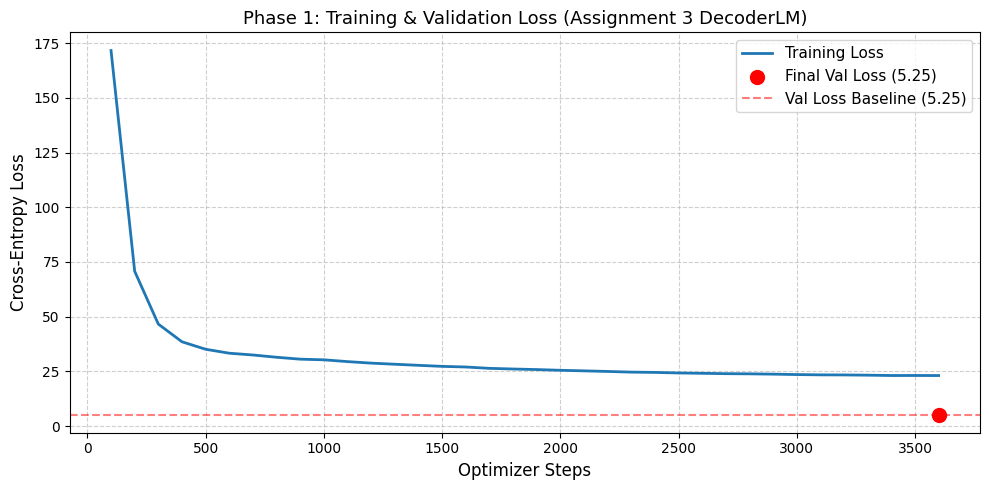

Loss plot saved to: /kaggle/working/cs781_phase1/training_validation_loss.png


In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Plot training loss curve
if train_steps:
    plt.plot(train_steps, train_loss, label="Training Loss", color="#1f77b4", linewidth=2)

# Plot validation loss evaluated at the end
if 'eval_loss' in locals() and train_steps:
    final_step = train_steps[-1]
    plt.scatter([final_step], [eval_loss], color="red", s=100, zorder=5, 
                label=f"Final Val Loss ({eval_loss:.2f})")
    plt.axhline(y=eval_loss, color="red", linestyle="--", alpha=0.5, 
                label=f"Val Loss Baseline ({eval_loss:.2f})")

plt.xlabel("Optimizer Steps", fontsize=12)
plt.ylabel("Cross-Entropy Loss", fontsize=12)
plt.title("Phase 1: Training & Validation Loss (Assignment 3 DecoderLM)", fontsize=13)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

print("Loss plot saved to:", LOSS_PLOT_PATH)

## 14. Save Final Model to Kaggle Output

In [16]:
# # trainer.save_model(MODEL_OUTPUT_DIR)
# tokenizer.save_pretrained(MODEL_OUTPUT_DIR)

# print("Final model saved to:")
# print(MODEL_OUTPUT_DIR)

NameError: name 'trainer' is not defined

## 15. Push Model to Hugging Face Hub

In [ ]:
# model.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)
# tokenizer.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)

# # print("Model and tokenizer pushed successfully.")

## 16. Load Test Data from HuggingFace

In [17]:
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Test file:", test_file_path)

test.json: 0.00B [00:00, ?B/s]

Test file: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


## 17. Load Test Prompts

In [18]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print("Number of test examples:", len(test_data))

Number of test examples: 1000


## 18. Generate 128 Words
#### (words, not tokens)

In [19]:
def generate_128_words(prompt_text, model, tokenizer, device, target_words=128):
    tokens = tokenizer.encode(prompt_text)
    max_prompt = MAX_SEQ_LEN - MAX_GENERATION_TOKENS
    if len(tokens) > max_prompt:
        tokens = tokens[-max_prompt:]
    prompt_len = len(tokens)
    full_tokens = model.generate(
        prompt_tokens=tokens,
        max_new_tokens=MAX_GENERATION_TOKENS,
        min_new_tokens=MIN_GENERATION_TOKENS,
        temperature=TEMPERATURE,
        top_p=TOP_P,
        repetition_penalty=REPETITION_PENALTY,
        device=device
    )
    gen_tokens = full_tokens[prompt_len:]
    gen_text = tokenizer.decode(gen_tokens).strip()
    # Enforce target sequence length
    words = gen_text.split()
    if len(words) >= target_words:
        continuation = " ".join(words[:target_words])
    else:
        continuation = " ".join(words)
    return continuation

## 20. Generate Predictions for the Test Set

In [20]:
predictions = {}
items = list(test_data.items())
total = len(items)
print(f"Generating 128-word continuations for {total} test prompts...")
for idx, (ex_id, rec) in enumerate(items):
    continuation = generate_128_words(rec["text"], model, tokenizer, device, target_words=TARGET_GENERATION_WORDS)
    predictions[str(ex_id)] = {"text": continuation}
    if (idx + 1) % 50 == 0 or (idx + 1) == total:
        print(f"Progress: {idx + 1}/{total} ({(idx + 1)/total*100:.1f}%)")
print("Inference completed!")

Generating 128-word continuations for 1000 test prompts...
Progress: 50/1000 (5.0%)
Progress: 100/1000 (10.0%)
Progress: 150/1000 (15.0%)
Progress: 200/1000 (20.0%)
Progress: 250/1000 (25.0%)
Progress: 300/1000 (30.0%)
Progress: 350/1000 (35.0%)
Progress: 400/1000 (40.0%)
Progress: 450/1000 (45.0%)
Progress: 500/1000 (50.0%)
Progress: 550/1000 (55.0%)
Progress: 600/1000 (60.0%)
Progress: 650/1000 (65.0%)
Progress: 700/1000 (70.0%)
Progress: 750/1000 (75.0%)
Progress: 800/1000 (80.0%)
Progress: 850/1000 (85.0%)
Progress: 900/1000 (90.0%)
Progress: 950/1000 (95.0%)
Progress: 1000/1000 (100.0%)
Inference completed!


## 21. Save prediction.json

In [21]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)

if os.path.exists(SUBMISSION_ZIP):
    os.remove(SUBMISSION_ZIP)
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

## 22. Create CodaBench Submission ZIP

In [22]:
with zipfile.ZipFile(SUBMISSION_ZIP, "r") as zipf:
    contents = zipf.namelist()
    print("Archive contents:", contents)
    assert contents == ["prediction.json"], "ERROR: Archive must contain ONLY prediction.json at root!"
print("\nSUCCESS! /kaggle/working/submission.zip is ready for Codabench submission.")

Archive contents: ['prediction.json']

SUCCESS! /kaggle/working/submission.zip is ready for Codabench submission.
